# Conecta+ · ¿A quién contactar y por qué se van?

Solución de la prueba técnica de Ciencia de Datos (nivel Senior). El notebook corre de principio a fin en
Google Colab: sube `datos_conecta.zip` al panel de archivos (o déjalo en tu Drive) y ejecuta *Entorno de ejecución → Ejecutar todo*.

**Cómo está organizado**

| Sección | Qué responde |
|---|---|
| 1. Datos y calidad | Qué hay en cada fuente, qué problemas tiene y cómo se resolvieron |
| 2. Etiquetas | Cómo se reconstruye el churn a 90 días y por qué se puede confiar en esa reconstrucción |
| 3. Texto de tickets | Cómo se aprovecha el texto (strands-decider + pysentimiento) y sus límites |
| 4. Variables | Qué sabe el modelo de cada cliente *a la fecha de corte* |
| 5. Modelos y MLflow | Validación temporal, 4 corridas y cuál se elige |
| 6. Efecto de los llamados | ¿Contaminan las etiquetas los contactos de retención? |
| 7. Decisión de contacto | A quién llamar, valor esperado y sensibilidad |
| 8. Hallazgos | Lo que la gerencia debería saber |
| 9. Producción | Cómo operarlo y qué vigilar |

La lógica está en el paquete `conecta/` (funciones probadas con `pytest`, carpeta `tests/`); este notebook orquesta y explica.

In [1]:
# Entorno: en Colab se clona el repositorio (para tener el paquete `conecta/`) y se ubica el zip de datos.
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/unfresh25/conecta-churn.git"

if IN_COLAB:
    if not Path("/content/repo/conecta").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Opción A: zip subido a /content. Opción B: descomentar para leerlo desde Drive.
    ZIP_PATH = Path("/content/datos_conecta.zip")
    # from google.colab import drive; drive.mount("/content/drive")
    # ZIP_PATH = Path("/content/drive/MyDrive/<ruta>/datos_conecta.zip")
else:
    ZIP_PATH = Path("datos_conecta.zip")

DATA_DIR = Path("datos")
if not (DATA_DIR / "conecta.db").exists():
    assert ZIP_PATH.exists(), f"No encuentro {ZIP_PATH}: sube datos_conecta.zip al entorno."
    zipfile.ZipFile(ZIP_PATH).extractall(DATA_DIR)
sys.path.insert(0, str(Path.cwd()))
print("Colab:", IN_COLAB, "| datos:", sorted(p.name for p in DATA_DIR.iterdir()))

Colab: False | datos: ['conecta.db', 'eventos.jsonl.gz', 'tickets.jsonl']


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SEED = 42
TODAY = pd.Timestamp("2025-12-31")

## 1. Datos y calidad

Tres sistemas distintos: la base relacional (`conecta.db`: clientes, suscripciones, facturas, etiquetas y clientes a puntuar),
la plataforma de atención (`tickets.jsonl`) y los logs de la app (`eventos.jsonl.gz`, solo 2025).
No hay diccionario de datos, así que cada supuesto sobre un campo queda escrito aquí.

In [3]:
from conecta.data import load_data, clean

raw = load_data(DATA_DIR)
data = clean(raw)
pd.DataFrame({
    "tabla": ["clientes", "suscripciones", "facturas", "etiquetas_entrenamiento", "clientes_a_puntuar", "tickets (registros)", "eventos"],
    "filas": [len(raw.clients), len(raw.subscriptions), len(raw.invoices), len(raw.labels), len(raw.to_score), len(raw.tickets_raw), len(raw.events)],
})

,tabla,filas
0,clientes,3000
1,suscripciones,3361
2,facturas,34138
3,etiquetas_entrenamiento,4693
4,clientes_a_puntuar,1556
5,tickets (registros),4452
6,eventos,103927


In [4]:
# Problemas encontrados y efecto de la limpieza (los conteos se recalculan con los datos)
reloads = len(raw.invoices) - raw.invoices["factura_id"].nunique()
quality = pd.DataFrame([
    ("ciudad: grafías distintas -> ciudades canónicas", f"{raw.clients['ciudad'].nunique()} -> {data.clients['ciudad'].nunique()}"),
    ("ciudad sin mapear (NaN)", int(data.clients["ciudad"].isna().sum())),
    ("edad inválida (0 o 999) -> NaN", int(data.clients["edad"].isna().sum())),
    ("facturas recargadas (mismo factura_id) eliminadas", reloads),
    ("cobros dobles reales (id distinto, mismo periodo) marcados", int(data.invoices["is_duplicate_charge"].sum())),
    ("facturas sin fecha_pago (impagas a hoy)", int(data.invoices["fecha_pago"].isna().sum())),
    ("eventos duplicados (event_id) eliminados", len(raw.events) - len(data.events)),
], columns=["problema", "valor"])
quality

,problema,valor
0,ciudad: grafías distintas -> ciudades canónicas,17 -> 6
1,ciudad sin mapear (NaN),0
2,edad inválida (0 o 999) -> NaN,65
3,facturas recargadas (mismo factura_id) eliminadas,677
4,"cobros dobles reales (id distinto, mismo perio...",699
5,facturas sin fecha_pago (impagas a hoy),1447
6,eventos duplicados (event_id) eliminados,1616


In [5]:
# Controles: si un conteo cambia, algo en la fuente o en la limpieza cambió y hay que investigarlo.
assert set(data.clients["ciudad"].dropna()) == {"Bogotá", "Medellín", "Cali", "Barranquilla", "Bucaramanga", "Pereira"}
assert data.clients["ciudad"].isna().sum() == 0
assert data.clients["edad"].isna().sum() == 65
assert reloads == 677 and data.invoices["is_duplicate_charge"].sum() == 699
assert len(raw.events) - len(data.events) == 1616
print("Controles de calidad OK")

Controles de calidad OK


**Supuestos y decisiones sobre los campos**

- `estado_actual` describe al cliente *hoy* (31-dic-2025), no en cada fecha de corte: ningún cliente "activo" aparece como churn en las etiquetas.
  Usarlo sería una fuga de información, así que **no se usa como variable**.
- `contactado_por_retencion` / `fecha_contacto_retencion`: el 90 % de los contactos de los clientes etiquetados ocurrió *después* del corte.
  Solo se usan contactos con fecha ≤ corte.
- `fecha_carga` es cuándo la factura entró al sistema (1 a 4 días después de iniciado el periodo). Una factura solo "existe" para el modelo
  si se cargó antes del corte.
- Una factura con el mismo `factura_id` repetido es una recarga del sistema (misma factura, otra `fecha_carga`); con id distinto para el
  mismo cliente, periodo y suscripción es un **cobro doble real** (ver hallazgos).
- `fecha_pago` vacía = no pagada a hoy. Para un corte pasado, una factura pagada después del corte cuenta como impaga en ese corte.
- `motivo_cancelacion = cambio_plan` cierra una suscripción y abre otra: no es churn.

### 1.1 Tickets: dos esquemas en un mismo archivo

`tickets.jsonl` mezcla dos formatos de la plataforma de atención. El **A** (2023-2025) trae `customer: "CL-012375"`, fechas en UTC,
`category` y `text`. El **B** (2025) trae el cliente anidado (`cliente.id`), fechas con zona `-05:00`, un `tipo` con categoría y
subcategoría, y una conversación (`mensajes`) en la que habla el cliente y responde el agente.

Se unifican en un solo esquema: `cliente_id` entero, fechas en hora de Bogotá, `text` = primer mensaje del **cliente**
(los mensajes del agente son 3 frases fijas y no aportan) y `status` abierto/cerrado.

In [6]:
from conecta.tickets import unify_tickets

data.tickets, dropped = unify_tickets(data.tickets_raw)
print(f"{len(data.tickets_raw)} registros -> {len(data.tickets)} tickets | descartados (cliente o fecha ilegible): {dropped}")
print("por esquema:", data.tickets["schema"].value_counts().to_dict())
print("textos únicos de cliente:", data.tickets["text"].nunique())
assert data.tickets["schema"].value_counts().to_dict() == {"A": 2553, "B": 1899} and dropped == 0

4452 registros -> 4452 tickets | descartados (cliente o fecha ilegible): 0
por esquema: {'A': 2553, 'B': 1899}
textos únicos de cliente: 38


## 2. Etiquetas: más cortes, misma definición

`etiquetas_entrenamiento` trae solo tres cortes (mar, jun y sep de 2025): 4.693 filas y 652 cancelaciones.
Es poco para entrenar y deja un único corte para validar. Pero la etiqueta se puede **reconstruir** desde `suscripciones`:

- un cliente está **activo** en la fecha *d* si tiene una suscripción con `fecha_inicio ≤ d` y (`fecha_fin` vacía o `> d`);
- `churn_90d = 1` si estaba activo en el corte y **no** tiene ninguna suscripción activa 90 días después.

Si esa regla reproduce exactamente las etiquetas entregadas, se puede aplicar a cada fin de mes de 2025 sin inventar una definición propia.

In [7]:
from conecta.labels import active_at, build_labels, monthly_cutoffs

official = data.labels.rename(columns={"fecha_corte": "cutoff", "churn_90d": "churn_official"})
mine = build_labels(data.subscriptions, sorted(official["cutoff"].unique()))
check = official.merge(mine, on=["cliente_id", "cutoff"], how="outer", indicator=True)
summary = check.groupby("cutoff").agg(
    filas_oficiales=("churn_official", "count"), filas_reconstruidas=("churn_90d", "count"),
    coincidencia=("churn_90d", lambda s: (s == check.loc[s.index, "churn_official"]).mean()),
)
summary

,filas_oficiales,filas_reconstruidas,coincidencia
cutoff,,,
2025-03-31,1387,1387,1.0
2025-06-30,1572,1572,1.0
2025-09-30,1734,1734,1.0


In [8]:
# Control: la reconstrucción coincide al 100 % (mismos clientes, misma etiqueta) en los tres cortes.
assert (check["_merge"] == "both").all()
assert (check["churn_90d"] == check["churn_official"]).all()
# Y los activos al 31-dic-2025 son exactamente los clientes a puntuar.
assert active_at(data.subscriptions, TODAY) == set(data.to_score["cliente_id"])
print("Etiquetas reconstruidas = etiquetas oficiales (100 %) | activos al 31-dic = clientes_a_puntuar")

Etiquetas reconstruidas = etiquetas oficiales (100 %) | activos al 31-dic = clientes_a_puntuar


**Panel de entrenamiento.** Cortes de fin de mes de enero a septiembre de 2025 (el 30-sep es el último cuya ventana de 90 días
termina antes del 31-dic). Se restringe a 2025 porque los logs de la app y el esquema B de tickets solo existen en 2025, y porque
2025 tuvo cambios de régimen (aumento del plan Básico en abril, app 5.2.0 en septiembre). El historial desde 2023 se prueba aparte
como una corrida de MLflow.

In [9]:
TRAIN_CUTOFFS = monthly_cutoffs("2025-01-31", "2025-09-30")
labels = build_labels(data.subscriptions, TRAIN_CUTOFFS)
by_cutoff = labels.groupby("cutoff")["churn_90d"].agg(clientes="size", churn="sum", tasa="mean")
display(by_cutoff.style.format({"tasa": "{:.1%}"}))
print(f"Panel 2025: {len(labels):,} filas, {labels['churn_90d'].sum():,} cancelaciones, "
      f"{labels['cliente_id'].nunique():,} clientes distintos")
assert len(labels) == 13600 and labels["churn_90d"].sum() == 1815

,clientes,churn,tasa
cutoff,,,
2025-01-31 00:00:00,1293,149,11.5%
2025-02-28 00:00:00,1332,151,11.3%
2025-03-31 00:00:00,1387,158,11.4%
2025-04-30 00:00:00,1439,158,11.0%
2025-05-31 00:00:00,1502,166,11.1%
2025-06-30 00:00:00,1572,211,13.4%
2025-07-31 00:00:00,1626,239,14.7%
2025-08-31 00:00:00,1715,300,17.5%
2025-09-30 00:00:00,1734,283,16.3%


Panel 2025: 13,600 filas, 1,815 cancelaciones, 2,253 clientes distintos


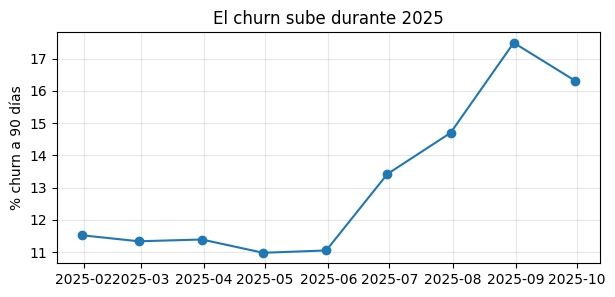

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_cutoff.index, by_cutoff["tasa"] * 100, marker="o")
ax.set_ylabel("% churn a 90 días"); ax.set_title("El churn sube durante 2025"); ax.grid(alpha=.3)
plt.show()

El churn pasa de ~11 % a ~17 % durante el año. Dos consecuencias para el diseño: la validación tiene que ser **temporal**
(entrenar con el pasado y evaluar en cortes posteriores, como ocurrirá en enero de 2026), y las probabilidades del modelo final
hay que **recalibrarlas** con los cortes más recientes, porque un modelo que promedia todo el año subestimaría el riesgo actual.

## 3. Texto de tickets: qué dice el cliente y en qué tono

Los 4.452 tickets usan solo **38 textos distintos**, y cerca de un tercio son **sarcásticos**
("Felicitaciones por la nueva versión, ahora la app se cierra sola… Genial"). De cada texto interesan cuatro cosas:
el **tema**, si el cliente **amenaza con irse**, y si está **molesto** (con enojo directo o con ironía).

**Qué se probó y por qué se eligió esta combinación** (detalle en `BITACORA_IA.md`), contra una referencia manual de los 38 textos:

| Enfoque | Resultado | ¿Se usa? |
|---|---|---|
| strands-decider (modelo de decisión de 2B, local): tema entre 8 opciones | 38/38 | Sí |
| strands-decider: ¿amenaza con irse? | 37/38 | Sí |
| strands-decider: sarcasmo / "¿está molesto?" (3 redacciones) | detecta 1-3 de 10 sarcásticos | No |
| pysentimiento (modelos en español): ironía | ordena perfecto (AUC 1,0); con corte 0,5 detecta 5/10 sin falsos positivos | Sí |
| pysentimiento: emoción "ira" | detecta 8 de 9 enojos directos | Sí |
| pysentimiento: sentimiento negativo | AUC 0,49: el sarcasmo sale "positivo" | No |
| TF-IDF / NLP clásico | con 38 textos únicos sería una tabla de búsqueda; el csat sigue al tema y no al tono, así que tampoco sirve como etiqueta débil | No |

**Regla:** `molesto = ira o ironía > 0,5`. El 0,5 es el corte natural del modelo; bajar el corte a ~0,1 detectaría 17/18 molestos,
pero sería ajustarlo mirando los mismos 38 textos con que se evalúa.

**Límites:** la referencia es chica (38 textos, 10 sarcásticos) y es un juicio humano; las probabilidades de ironía son poco graduadas;
strands-decider es una librería experimental. En producción, un texto nuevo se clasifica en vivo y si la confianza es baja va a revisión humana.

**Reproducibilidad:** la clasificación se calcula una vez, se revisa a mano y se guarda en `data_derivada/tickets_clasificados.csv`,
indexada por un hash del texto (el repositorio no publica textos de clientes). Con `RECALCULATE_NLP = True` se regenera en Colab
(instala strands-decider y pysentimiento y levanta el servidor del modelo; tarda unos minutos).

In [11]:
from conecta.tickets import DECIDER_MODEL, classify_texts, hash_text, load_classification

RECALCULATE_NLP = False
CLASSIFICATION_PATH = Path("data_derivada/tickets_clasificados.csv")

if RECALCULATE_NLP:
    import time, urllib.request
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "strands-decider", "pysentimiento"], check=True)
    server = subprocess.Popen(["strands-decider", "serve", DECIDER_MODEL, "--port", "8765"],
                              stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(180):  # hasta 15 minutos para descargar y calentar el modelo
        try:
            urllib.request.urlopen("http://127.0.0.1:8765/health", timeout=5); break
        except Exception:
            time.sleep(5)
    try:
        classify_texts(data.tickets["text"].dropna().unique().tolist()).to_csv(CLASSIFICATION_PATH, index=False)
    finally:
        server.terminate()

classification = load_classification(CLASSIFICATION_PATH)
data.tickets["hash"] = data.tickets["text"].map(hash_text, na_action="ignore")
coverage = data.tickets["hash"].isin(classification["hash"]).mean()
print(f"Textos clasificados: {len(classification)} | tickets cubiertos por la clasificación: {coverage:.1%}")

Textos clasificados: 38 | tickets cubiertos por la clasificación: 100.0%


In [12]:
# ¿Coincide el tema que asigna el modelo con la categoría que registró la plataforma? (validación independiente)
tk = data.tickets.merge(classification, on="hash", how="left")
pd.crosstab(tk["source_topic"], tk["topic"])

topic,acceso_cuenta,app_se_cierra,aumento_precio,cambio_plan,cancelar,cobro_doble,cobro_no_reconocido,lentitud
source_topic,,,,,,,,
app_se_cierra,0,816,0,0,0,0,0,0
cambio_clave,640,0,0,0,0,0,0,0
cambio_plan,0,0,0,328,0,0,0,0
cancelar,0,0,0,0,722,0,0,0
cobro_doble,0,0,0,0,0,699,0,0
lentitud,0,0,0,0,0,0,0,876
no_reconoce_cobro,0,0,175,0,0,0,196,0


El tema del modelo coincide con la categoría de la plataforma en todos los casos, salvo uno que **agrega información**:
lo que la plataforma registra como `no_reconoce_cobro` es en realidad de dos tipos. Casi la mitad son quejas por el
**aumento de precio sin aviso** ("Me subieron la tarifa sin avisar…"). La plataforma no distingue ese motivo; el texto sí.

In [13]:
summary = tk.groupby("topic").agg(tickets=("ticket_id", "size"), amenaza=("p_threat", lambda s: (s > .5).mean()),
                                  molesto=("annoyed", "mean"), csat=("csat", "mean"))
summary.sort_values("tickets", ascending=False).style.format({"amenaza": "{:.0%}", "molesto": "{:.0%}", "csat": "{:.2f}"})

,tickets,amenaza,molesto,csat
topic,,,,
lentitud,876,0%,29%,3.36
app_se_cierra,816,18%,56%,2.48
cancelar,722,100%,17%,3.72
cobro_doble,699,12%,60%,2.79
acceso_cuenta,640,0%,0%,3.31
cambio_plan,328,33%,0%,3.42
cobro_no_reconocido,196,0%,0%,3.40
aumento_precio,175,0%,100%,3.46
